In [7]:
# Testen der Adjoint Methode (also default)
import numpy as np
from NN import Neural_ODE_MLP

np.random.seed(42)
model = Neural_ODE_MLP(layers=20, dim_state=1, method ='adjoint')
model.read_data("logistic_data.csv")

learning_rate = 1e-3
for epoch in range(5000):
    loss, learning_rate_used = model.train_step()
    learning_rate = learning_rate_used                     # nächste Iteration startet mit akzeptierter lr

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss:.6f}, Learning rate = {learning_rate:.2e}")

Epoch 0: Loss = 64.050214, Learning rate = 1.10e-03
Epoch 100: Loss = 3.454311, Learning rate = 2.75e-04
Epoch 200: Loss = 2.805933, Learning rate = 1.38e-04
Epoch 300: Loss = 2.453606, Learning rate = 1.10e-03
Epoch 400: Loss = 2.208742, Learning rate = 1.10e-03
Epoch 500: Loss = 2.018392, Learning rate = 2.75e-04
Epoch 600: Loss = 1.854428, Learning rate = 1.38e-04
Epoch 700: Loss = 1.715971, Learning rate = 2.75e-04
Epoch 800: Loss = 1.585135, Learning rate = 5.50e-04
Epoch 900: Loss = 1.432191, Learning rate = 2.75e-04
Epoch 1000: Loss = 1.246224, Learning rate = 5.50e-04
Epoch 1100: Loss = 0.995838, Learning rate = 1.10e-03
Epoch 1200: Loss = 0.708262, Learning rate = 2.75e-04
Epoch 1300: Loss = 0.462667, Learning rate = 2.75e-04
Epoch 1400: Loss = 0.324253, Learning rate = 2.75e-04
Epoch 1500: Loss = 0.204985, Learning rate = 5.50e-04
Epoch 1600: Loss = 0.112040, Learning rate = 2.75e-04
Epoch 1700: Loss = 0.054358, Learning rate = 1.10e-03
Epoch 1800: Loss = 0.027501, Learning r

In [2]:
# Testen der Sensitivity Methode
import numpy as np
from NN import Neural_ODE_MLP

np.random.seed(42)
model_sensitivity = Neural_ODE_MLP(layers=20, dim_state=1, method ='sensitivity')
model_sensitivity.read_data("logistic_data.csv")

learning_rate = 1e-3
for epoch in range(10000):
    loss, learning_rate_used = model_sensitivity.train_step()
    learning_rate = learning_rate_used                     # nächste Iteration startet mit akzeptierter lr

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss:.6f}, Learning rate = {learning_rate:.2e}")

Epoch 0: Loss = 64.285578, Learning rate = 1.10e-03
Epoch 100: Loss = 3.432206, Learning rate = 2.75e-04
Epoch 200: Loss = 2.781478, Learning rate = 1.38e-04
Epoch 300: Loss = 2.628940, Learning rate = 1.38e-04
Epoch 400: Loss = 2.544936, Learning rate = 1.38e-04
Epoch 500: Loss = 2.472196, Learning rate = 1.38e-04
Epoch 600: Loss = 2.397426, Learning rate = 1.38e-04
Epoch 700: Loss = 2.317599, Learning rate = 1.38e-04
Epoch 800: Loss = 2.232240, Learning rate = 1.38e-04
Epoch 900: Loss = 2.140527, Learning rate = 1.38e-04
Epoch 1000: Loss = 2.041877, Learning rate = 1.38e-04
Epoch 1100: Loss = 1.936347, Learning rate = 1.38e-04
Epoch 1200: Loss = 1.823790, Learning rate = 1.38e-04
Epoch 1300: Loss = 1.703293, Learning rate = 1.38e-04
Epoch 1400: Loss = 1.567003, Learning rate = 5.50e-04
Epoch 1500: Loss = 1.418106, Learning rate = 1.38e-04
Epoch 1600: Loss = 1.245612, Learning rate = 1.38e-04
Epoch 1700: Loss = 1.013413, Learning rate = 1.10e-03
Epoch 1800: Loss = 0.783380, Learning r

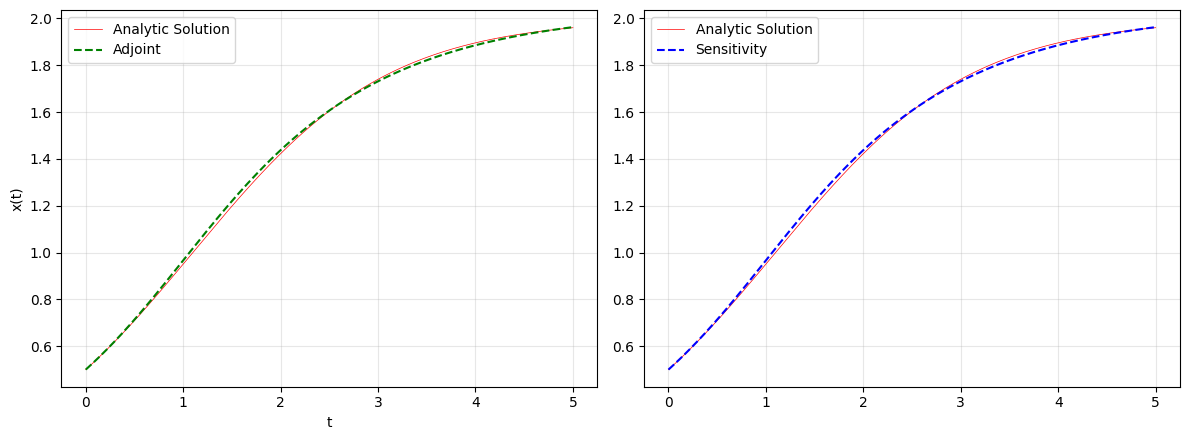

In [17]:
import matplotlib.pyplot as plt
def logistics_analytic(x0,t):
    # x' = 1/2 * x * (2-x) -> x=2x0 / ((2-x0)*exp(t-t0) + x0)
    return (2*x0)/((2-x0)*np.exp(-t)+x0)

x0 = 0.5
T  = 5.0
N  = 200

time_grid = np.linspace(0.0, T, N)
h = time_grid[1] - time_grid[0]          # = T/(N-1)


# Auswertung mittels gelernter Dynamik
def f_adj(x):
    x = np.array([[x]])                                                 # (n=1, M=1)
    z = model.W1 @ x + model.b1[:, None]                                # (h, 1)
    a = np.tanh(z)                                                      # (h, 1)
    Output = model.WN @ a + model.bN[:, None]                           # (1,1)
    return Output[0][0]

def f_sen(x):
    x = np.array([[x]])                                                 # (n=1, M=1)
    z = model_sensitivity.W1 @ x + model_sensitivity.b1[:, None]        # (h, 1)
    a = np.tanh(z)                                                      # (h, 1)
    Output = model_sensitivity.WN @ a + model_sensitivity.bN[:, None]   # (1,1)
    return Output[0][0]

x_rk4_adj = np.zeros(N)
x_rk4_sen = np.zeros(N)
x_rk4_adj[0] = x0
x_rk4_sen[0] = x0
for i in range(N-1):
    # Adjoint 
    k1_adj = f_adj(x_rk4_adj[i])
    k2_adj = f_adj(x_rk4_adj[i] + h/2 * k1_adj)
    k3_adj = f_adj(x_rk4_adj[i] + h/2 * k2_adj)
    k4_adj = f_adj(x_rk4_adj[i] + h * k3_adj)
    x_rk4_adj[i+1] = x_rk4_adj[i] + h/6 * (k1_adj + 2*k2_adj + 2*k3_adj + k4_adj)

    # Sensitivity
    k1_sen = f_adj(x_rk4_sen[i])
    k2_sen = f_adj(x_rk4_sen[i] + h/2 * k1_sen)
    k3_sen = f_adj(x_rk4_sen[i] + h/2 * k2_sen)
    k4_sen = f_adj(x_rk4_sen[i] + h * k3_sen)
    x_rk4_sen[i+1] = x_rk4_sen[i] + h/6 * (k1_sen + 2*k2_sen + 2*k3_sen + k4_sen)

# Analytik
x_exact = logistics_analytic(x0, time_grid)

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(time_grid, x_exact, 'r-',  lw=0.5,   label='Analytic Solution')
ax1.plot(time_grid, x_rk4_adj,   'g--', lw=1.5, label='Adjoint')
ax2.plot(time_grid, x_exact, 'r-',  lw=0.5,   label='Analytic Solution')
ax2.plot(time_grid, x_rk4_sen,   'b--', lw=1.5, label='Sensitivity')
ax1.set_xlabel('t'); 
ax1.set_ylabel('x(t)')
ax1.legend(); 
ax2.legend(); 
ax1.grid(alpha=0.3)
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

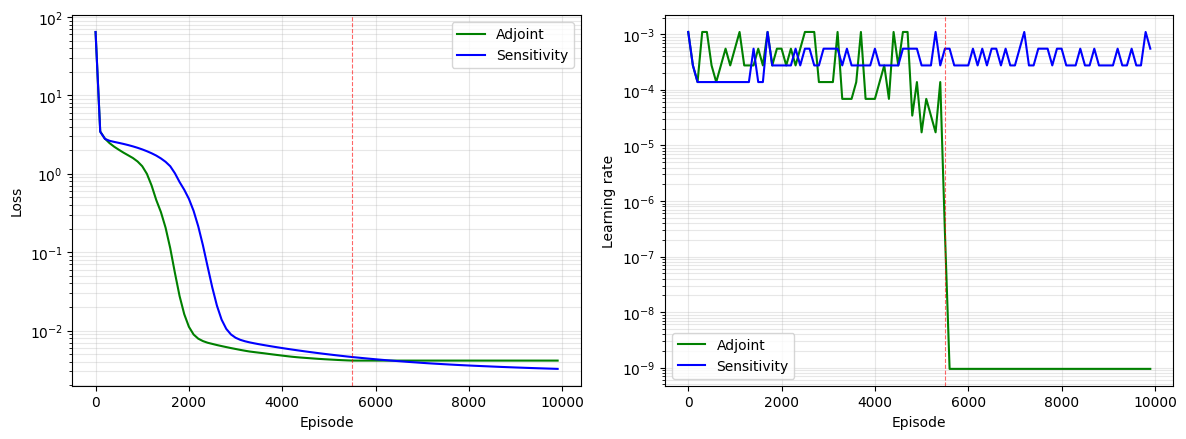

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Daten aus meinem Testlauf mit h=20 und 10.000 Episoden mit einem Cut bei 5700
adj = np.loadtxt("adjoint_loss.csv", delimiter=",", skiprows=1)
sen = np.loadtxt("sensitivity_loss.csv", delimiter=",", skiprows=1)

epochs_adj, losses_adj, lrs_adj = adj[:,0], adj[:,1], adj[:,2]
epochs_sen, losses_sen, lrs_sen = sen[:,0], sen[:,1], sen[:,2]

# --- Zwei Subplots nebeneinander ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Links: Loss vs. Epoche (log-y), beide Methoden
ax1.semilogy(epochs_adj, losses_adj, 'g-', lw=1.5, label='Adjoint')
ax1.semilogy(epochs_sen, losses_sen, 'b-', lw=1.5, label='Sensitivity')
ax1.set_xlabel('Episode')
ax1.set_ylabel('Loss')
ax1.grid(True, which='both', alpha=0.3)
ax1.legend()
ax1.axvline(5500, color='red', ls='--', lw=0.8, alpha=0.6)

# Rechts: Lernrate vs. Epoche (log-y), beide Methoden
ax2.semilogy(epochs_adj, lrs_adj, 'g-', lw=1.5, label='Adjoint')
ax2.semilogy(epochs_sen, lrs_sen, 'b-', lw=1.5, label='Sensitivity')
ax2.set_xlabel('Episode')
ax2.set_ylabel('Learning rate')
ax2.grid(True, which='both', alpha=0.3)
ax2.legend()
ax2.axvline(5500, color='red', ls='--', lw=0.8, alpha=0.6)

plt.tight_layout()
plt.savefig("training_comparison.png", dpi=150)
plt.show()